<a href="https://colab.research.google.com/github/Nayemuzzaman007/Wifi-2.4-GHz-channel-with-RIS-panel-/blob/main/PRISM_journal_current_working_model_september.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
import os
import shutil

# Check if the mount point exists and is not empty
if os.path.exists('/content/drive') and os.listdir('/content/drive'):
    print("Clearing existing mount point...")
    # Use caution: this removes the local folder to allow mounting
    try:
        shutil.rmtree('/content/drive')
    except OSError:
        # If it's already a mounted drive, unmount it first
        !fusermount -u /content/drive

# Now mount the drive
drive.mount('/content/drive', force_remount=True)

Clearing existing mount point...
Mounted at /content/drive


After running the above cell and authorizing Google Drive access, the simulation outputs will be saved to the specified path within your Google Drive.

In [ ]:
OUT_DIR = Path("/content/drive/MyDrive/multiroom_wifi_RIS_September_new")
OUT_DIR.mkdir(parents=True, exist_ok=True)

### 1. Scene Generation & Building Layout
Run this cell to generate the 6-room floorplan with seed 42. You can verify the `multiroom_wifi_2ghz/scene.xml` file after execution.

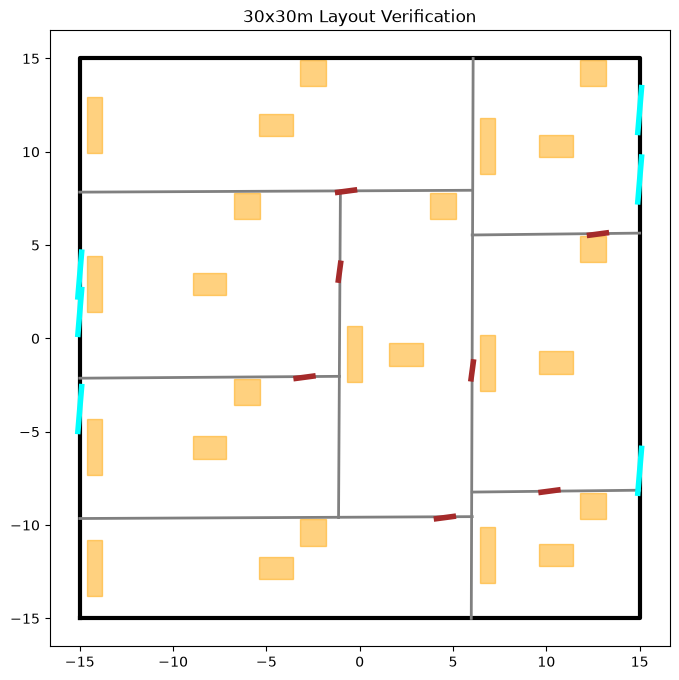

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# --- SCENE CONFIGURATION ---
SCENE_SEED = 42
TARGET_ROOMS = 8
PLANE_HALF = 15.0 # 30m total width
ROOM_LZ = 3.0
OUT_DIR = Path("multiroom_wifi_2ghz")
OUT_DIR.mkdir(parents=True, exist_ok=True)

def write_scene_xml(xml_path, walls, openings, furniture):
    hz, whz = ROOM_LZ/2.0, ROOM_LZ*0.8/2.0
    # Note: 'material_type' was changed to 'type' to satisfy the itu-radio-material plugin requirements
    lines = [
        '<scene version="3.0.0">',
        '<bsdf type="itu-radio-material" id="mat-concrete"><string name="type" value="concrete"/></bsdf>',
        '<bsdf type="itu-radio-material" id="mat-plasterboard"><string name="type" value="plasterboard"/></bsdf>',
        '<bsdf type="itu-radio-material" id="mat-wood"><string name="type" value="wood"/></bsdf>',
        '<bsdf type="itu-radio-material" id="mat-glass"><string name="type" value="glass"/></bsdf>'
    ]
    lines += [f'<shape type="cube" id="floor"><transform name="to_world"><scale x="{PLANE_HALF}" y="{PLANE_HALF}" z="0.1"/><translate x="0" y="0" z="-0.1"/></transform><ref id="mat-concrete"/></shape>']

    for i, w in enumerate(walls):
        lines.append(f'<shape type="cube" id="wall_{i}"><transform name="to_world"><scale x="{w["sx"]}" y="{w["sy"]}" z="{whz}"/><translate x="{w["cx"]}" y="{w["cy"]}" z="{whz}"/></transform><ref id="mat-plasterboard"/></shape>')

    for i, o in enumerate(openings):
        mat = "mat-glass" if o["type"] == "window" else "mat-wood"
        lines.append(f'<shape type="cube" id="opening_{i}"><transform name="to_world"><scale x="{o["sx"]}" y="{o["sy"]}" z="{o["sz"]}"/><translate x="{o["cx"]}" y="{o["cy"]}" z="{o["cz"]}"/></transform><ref id="{mat}"/></shape>')

    for i, f in enumerate(furniture):
        lines.append(f'<shape type="cube" id="furn_{i}"><transform name="to_world"><scale x="{f["sx"]}" y="{f["sy"]}" z="{f["sz"]}"/><translate x="{f["cx"]}" y="{f["cy"]}" z="{f["cz"]}"/></transform><ref id="mat-wood"/></shape>')

    lines.append("</scene>")
    xml_path.write_text("\n".join(lines))

def generate_complex_layout(seed):
    rng = np.random.default_rng(seed)
    rooms = [{"x0":-PLANE_HALF, "x1":PLANE_HALF, "y0":-PLANE_HALF, "y1":PLANE_HALF}]
    walls = []
    openings = []
    furniture = []

    while len(rooms) < TARGET_ROOMS:
        rooms.sort(key=lambda r:(r["x1"]-r["x0"])*(r["y1"]-r["y0"]), reverse=True)
        room = rooms.pop(0)
        if (room["x1"]-room["x0"]) >= (room["y1"]-room["y0"]):
            sv = rng.uniform(room["x0"]+4.0, room["x1"]-4.0)
            rooms += [{"x0":room["x0"],"x1":sv, "y0":room["y0"],"y1":room["y1"]}, {"x0":sv,"x1":room["x1"], "y0":room["y0"],"y1":room["y1"]}]
            walls.append({"cx":sv, "cy":(room["y0"]+room["y1"])/2, "sx":0.05, "sy":(room["y1"]-room["y0"])/2})
            openings.append({"type":"door", "cx":sv, "cy":rng.uniform(room["y0"]+1.0, room["y1"]-1.0), "cz":1.0, "sx":0.06, "sy":0.45, "sz":1.0})
        else:
            sv = rng.uniform(room["y0"]+4.0, room["y1"]-4.0)
            rooms += [{"x0":room["x0"],"x1":room["x1"], "y0":room["y0"],"y1":sv}, {"x0":room["x0"],"x1":room["x1"], "y0":sv,"y1":room["y1"]}]
            walls.append({"cx":(room["x0"]+room["x1"])/2, "cy":sv, "sx":(room["x1"]-room["x0"])/2, "sy":0.05})
            openings.append({"type":"door", "cx":rng.uniform(room["x0"]+1.0, room["x1"]-1.0), "cy":sv, "cz":1.0, "sx":0.45, "sy":0.06, "sz":1.0})

    for _ in range(6):
        side = rng.choice([-PLANE_HALF, PLANE_HALF])
        openings.append({"type":"window", "cx":side, "cy":rng.uniform(-PLANE_HALF+2, PLANE_HALF-2), "cz":1.5, "sx":0.1, "sy":1.2, "sz":0.6})

    for r in rooms:
        cx, cy = (r["x0"]+r["x1"])/2, (r["y0"]+r["y1"])/2
        furniture.append({"cx":cx, "cy":cy, "cz":0.4, "sx":0.9, "sy":0.6, "sz":0.4})
        furniture.append({"cx":r["x0"]+0.8, "cy":cy, "cz":0.9, "sx":0.4, "sy":1.5, "sz":0.9})
        furniture.append({"cx":cx+2.0, "cy":r["y1"]-0.8, "cz":0.3, "sx":0.7, "sy":0.7, "sz":0.3})

    return walls, openings, furniture

walls, openings, furniture = generate_complex_layout(SCENE_SEED)
write_scene_xml(OUT_DIR/"scene.xml", walls, openings, furniture)

plt.figure(figsize=(8,8))
plt.gca().set_aspect("equal")
plt.plot([-PLANE_HALF, PLANE_HALF, PLANE_HALF, -PLANE_HALF, -PLANE_HALF], [-PLANE_HALF, -PLANE_HALF, PLANE_HALF, PLANE_HALF, -PLANE_HALF], "k", lw=3)
for w in walls:
    plt.plot([w["cx"]-w["sx"], w["cx"]+w["sx"]], [w["cy"]-w["sy"], w["cy"]+w["sy"]], "gray", lw=2)
for o in openings:
    color = "brown" if o["type"] == "door" else "cyan"
    plt.plot([o["cx"]-o["sx"], o["cx"]+o["sx"]], [o["cy"]-o["sy"], o["cy"]+o["sy"]], color, lw=4)
for f in furniture:
    rect = plt.Rectangle((f["cx"]-f["sx"], f["cy"]-f["sy"]), 2*f["sx"], 2*f["sy"], color="orange", alpha=0.5)
    plt.gca().add_patch(rect)

plt.title("30x30m Layout Verification")
plt.show()

### Quick Scene Verification
Run this cell to see a 3D preview of your 8-room environment and furniture.

### 2. Prepare Main Simulation Parameters
After verifying the scene, you can run the main simulation. This block defines the updated array types and RIS placement.

In [ ]:
import numpy as np
import mitsuba as mi
from sionna.rt import PlanarArray, AntennaArray
from sionna.rt.antenna_pattern import antenna_pattern_registry

# Updated parameters based on user request
RIS_ELEMENTS_DIM = 40
RIS_N = RIS_ELEMENTS_DIM * RIS_ELEMENTS_DIM # 1600 elements
NUM_SELECTED = 8
AP_ANTENNAS = 6

def make_user_array():
    # 1 antenna element for user device
    return PlanarArray(num_rows=1, num_cols=1,
                       vertical_spacing=0.5, horizontal_spacing=0.5,
                       pattern="dipole", polarization="V")

def make_ap_array():
    # 6-element Uniform Circular Array (UCA) with lambda/2 spacing
    # In Sionna RT 2.x, spacing is normalized to units of wavelength
    d_norm = 0.5
    radius_norm = d_norm / (2 * np.sin(np.pi / AP_ANTENNAS))

    # Manually calculate element positions for a UCA in the y-z plane (x=0)
    # This matches the local frame convention where x is boresight
    angles = np.linspace(0, 2*np.pi, AP_ANTENNAS, endpoint=False)
    y = radius_norm * np.cos(angles)
    z = radius_norm * np.sin(angles)
    x = np.zeros(AP_ANTENNAS)

    normalized_positions = mi.Point3f(x, y, z)

    # Build the AntennaPattern instance via the registry (internal Sionna convention)
    antenna_pattern = antenna_pattern_registry.get("dipole")(
        polarization="V",
        polarization_model="tr38901_2",
    )

    return AntennaArray(antenna_pattern=antenna_pattern,
                        normalized_positions=normalized_positions)

def make_ris_array():
    # 40x40 RIS Planar Array
    return PlanarArray(num_rows=RIS_ELEMENTS_DIM, num_cols=RIS_ELEMENTS_DIM,
                       vertical_spacing=0.5, horizontal_spacing=0.5,
                       pattern="iso", polarization="V")

# Access Point and RIS panel placement
ap_pos = [2.0, 2.0, 2.8]
ris_panels = [
    {"cx": ap_pos[0] + 2.0, "cy": ap_pos[1], "cz": 2.0, "normal": [-1.0, 0.0, 0.0]}
]

print(f"Main config fixed for Sionna RT 2.x: AP=6-element UCA (normalized), User=1-element, RIS={RIS_ELEMENTS_DIM}x{RIS_ELEMENTS_DIM}")

Main config fixed for Sionna RT 2.x: AP=6-element UCA (normalized), User=1-element, RIS=40x40


### Quick Simulation Test
Run a mini-simulation on 5 positions to verify the logic before the full 21,025 position run.

In [ ]:
import os, sys, time, gc
import hdf5storage
import drjit as dr
import numpy as np
from pathlib import Path
from sionna.rt import load_scene, Transmitter, Receiver, PathSolver, subcarrier_frequencies

# --- CONFIGURATION ---
FREQ_HZ = 2.4e9
TX_GRID_STEP = 1
PLANE_HALF = 15.0
NUM_SUBCARRIERS = 64
# Note: scattering is enabled at the shape level, not as a solver argument
PATH_CFG = dict(max_depth=6, los=True, specular_reflection=True, diffraction=True, synthetic_array=True)

# --- QUICK TEST TOGGLE ---
IS_QUICK_TEST = False

DRIVE_DIR = Path("/content/drive/MyDrive/multiroom_wifi_RIS_September_new")
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

scene_path = DRIVE_DIR / 'scene.xml'
if not scene_path.exists():
    print(f"Generating scene in {DRIVE_DIR}...")
    walls, openings, furniture = generate_complex_layout(SCENE_SEED)
    try:
        write_scene_xml(scene_path, walls, openings, furniture)
    except TypeError:
        write_scene_xml(scene_path, walls)

def ris_orientation(n):
    return [float(np.arctan2(n[1], n[0])), 0.0, 0.0]

NUM_SELECTED = 8
_ALL_FREQS = np.array(subcarrier_frequencies(NUM_SUBCARRIERS, 312500.0))
f_step = NUM_SUBCARRIERS // NUM_SELECTED
f_sel_idx = list(range(f_step // 2, NUM_SUBCARRIERS, f_step))[:NUM_SELECTED]
FREQUENCIES = _ALL_FREQS[f_sel_idx]

xs = np.arange(-PLANE_HALF+0.5, PLANE_HALF-0.5, TX_GRID_STEP, dtype=np.float32)
ys = np.arange(-PLANE_HALF+0.5, PLANE_HALF-0.5, TX_GRID_STEP, dtype=np.float32)
full_user_pos = np.array([[x, y, 1.2] for x in xs for y in ys], dtype=np.float32)

if IS_QUICK_TEST:
    print("!!! RUNNING IN QUICK TEST MODE !!!")
    user_pos = full_user_pos[:5]
else:
    user_pos = full_user_pos

N = len(user_pos)
solver = PathSolver()

# --- PASS A: Direct Path (User -> AP) ---
print(f"Starting PASS A (Direct) for {N} positions...")
scene_a = load_scene(str(scene_path))
# Enable scattering for all shapes in the scene
for obj in scene_a.objects.values():
    obj.scattering = True

scene_a.frequency = FREQ_HZ
scene_a.tx_array = make_user_array()
scene_a.rx_array = make_ap_array()
scene_a.add(Receiver(name='ap', position=ap_pos))
h_d = np.zeros((N, AP_ANTENNAS, NUM_SELECTED), dtype=np.complex64)

file_a = 'h_d_test.mat' if IS_QUICK_TEST else 'h_d.mat'
for b in range(N):
    if b % 100 == 0: dr.flush_malloc_cache()
    scene_a.add(Transmitter(name='u', position=user_pos[b].tolist()))
    paths = solver(scene=scene_a, **PATH_CFG)
    h_val = np.asarray(paths.cfr(frequencies=FREQUENCIES, out_type='numpy'))
    h_d[b] = np.squeeze(h_val)
    scene_a.remove('u')

    if (b + 1) % 100 == 0 or (b + 1) == N:
        hdf5storage.savemat(str(DRIVE_DIR / file_a), {'h_d': h_d, 'grid_x': xs, 'grid_y': ys})
        print(f"Pass A progress: {b+1}/{N} saved.")

# --- PASS B: User -> RIS Path ---
print(f"Starting PASS B (User-RIS) for {N} positions...")
scene_b = load_scene(str(scene_path))
for obj in scene_b.objects.values():
    obj.scattering = True

scene_b.frequency = FREQ_HZ
scene_b.tx_array = make_user_array()
scene_b.rx_array = make_ris_array()
for i, rp in enumerate(ris_panels):
    scene_b.add(Receiver(name=f'r{i}', position=[rp['cx'], rp['cy'], rp['cz']], orientation=ris_orientation(rp['normal'])))

h_ur = np.zeros((N, len(ris_panels), NUM_SELECTED, RIS_N), dtype=np.complex64)
file_b = 'h_ur_test.mat' if IS_QUICK_TEST else 'h_ur.mat'
for b in range(N):
    if b % 50 == 0: (dr.flush_malloc_cache(), gc.collect())
    scene_b.add(Transmitter(name='u', position=user_pos[b].tolist()))
    paths = solver(scene=scene_b, **PATH_CFG)
    h = np.asarray(paths.cfr(frequencies=FREQUENCIES, out_type='numpy')).reshape(len(ris_panels), RIS_N, NUM_SELECTED)
    h_ur[b] = np.transpose(h, (0, 2, 1))
    scene_b.remove('u')

    if (b + 1) % 100 == 0 or (b + 1) == N:
        hdf5storage.savemat(str(DRIVE_DIR / file_b), {'h_ur': h_ur, 'grid_x': xs, 'grid_y': ys})
        print(f"Pass B progress: {b+1}/{N} saved.")

# --- PASS C: AP -> RIS Path (Fixed Channel) ---
print("Starting PASS C (AP-RIS) - Fixed channel calculation...")
scene_c = load_scene(str(scene_path))
for obj in scene_c.objects.values():
    obj.scattering = True

scene_c.frequency = FREQ_HZ
scene_c.tx_array = make_ap_array()
scene_c.rx_array = make_ris_array()
scene_c.add(Transmitter(name='ap_tx', position=ap_pos))
for i, rp in enumerate(ris_panels):
    scene_c.add(Receiver(name=f'r{i}', position=[rp['cx'], rp['cy'], rp['cz']], orientation=ris_orientation(rp['normal'])))

paths_c = solver(scene=scene_c, **PATH_CFG)
h_ar_raw = np.asarray(paths_c.cfr(frequencies=FREQUENCIES, out_type='numpy'))
h_ar = h_ar_raw.reshape(len(ris_panels), RIS_N, AP_ANTENNAS, NUM_SELECTED)
h_ar = np.transpose(h_ar, (0, 2, 3, 1))

file_c = 'h_ar_test.mat' if IS_QUICK_TEST else 'h_ar.mat'
hdf5storage.savemat(str(DRIVE_DIR / file_c), {'h_ar': h_ar})
print(f"Pass C saved to {file_c}")

print(f"SUCCESS! Individual files updated in Google Drive directory: {DRIVE_DIR}")

Starting PASS A (Direct) for 841 positions...
Pass A progress: 100/841 saved.
Pass A progress: 200/841 saved.
Pass A progress: 300/841 saved.
Pass A progress: 400/841 saved.
Pass A progress: 500/841 saved.
Pass A progress: 600/841 saved.
Pass A progress: 700/841 saved.


ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sionna/rt/path_solvers/sb_candidate_generator.py", line 367, in _loop_body
    s, n, wedges = self._sample_radio_material(si_scene, ray.o, ray.d,
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                                               active)
                                               ^^^
  File "/usr/local/lib/python3.13/dist-packages/sionna/rt/path_solvers/sb_candidate_generator.py", line 645, in _sample_radio_material
    sample, _ = si.bsdf().sample(ctx, si, sample1, sample2, active)
                ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sionna/rt/radio_materials/radio_material.py", line 422, in sample
    ko_diffr_local = self._diffraction_direction(si, sample2.x,
                                                ki_local)
  File "/usr/local/lib/python3.13/dist-packages/sionna/rt/radio_mat

TypeError: object of type 'NoneType' has no len()

Using in-memory results (841 points).

=== Direct AP Path ===
  Max : -45.53 dB
  Mean: -65.62 dB
  Min : -96.23 dB

=== RIS Hop (user -> RIS), ideal coherent combining across elements ===
  Max :  21.79 dB
  Mean:  -4.07 dB


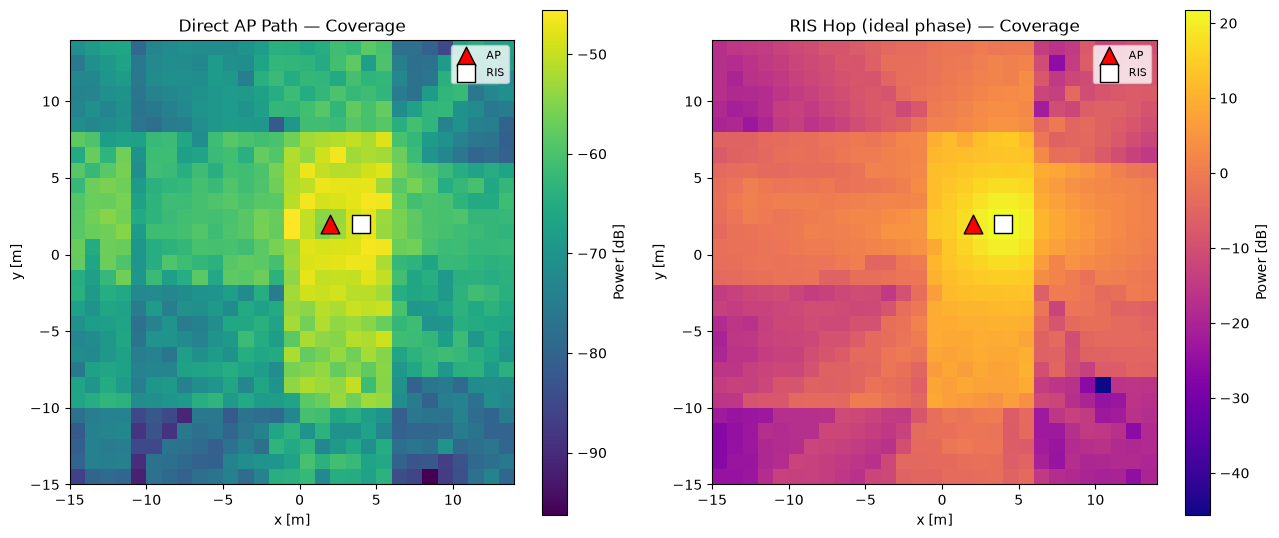

In [ ]:
# ==============================================================
# CELL 3: Coverage Map + Direct-Path vs RIS-Hop Signal Strength
# ==============================================================
import numpy as np
import matplotlib.pyplot as plt

# --- Pull results either from memory (just ran cell 2) or from disk ---
try:
    _h_d, _h_ur, _pos = h_d, h_ur, user_pos
    print(f"Using in-memory results ({len(_pos)} points).")
except NameError:
    import hdf5storage
    # Note: Check these filenames match what Pass A/B/C actually save
    load_path_a = DRIVE_DIR / ('h_d_test.mat' if IS_QUICK_TEST else 'h_d.mat')
    load_path_b = DRIVE_DIR / ('h_ur_test.mat' if IS_QUICK_TEST else 'h_ur.mat')

    print(f"No live variables found, loading from {DRIVE_DIR} ...")
    _mat_a = hdf5storage.loadmat(str(load_path_a))
    _mat_b = hdf5storage.loadmat(str(load_path_b))

    _h_d = _mat_a['h_d']
    _h_ur = _mat_b['h_ur']
    _gx, _gy = _mat_a['grid_x'].ravel(), _mat_a['grid_y'].ravel()
    _pos = np.array([[x, y, 1.2] for x in _gx for y in _gy], dtype=np.float32)

N = _h_d.shape[0]

# --- Per-position channel strength metrics ---
# Direct path: average received power across AP antennas + subcarriers [dB]
direct_power_lin = np.mean(np.abs(_h_d) ** 2, axis=(1, 2))          # (N,)
direct_power_dB  = 10 * np.log10(direct_power_lin + 1e-30)

# RIS hop (user -> RIS only):
# "ideal coherent" gain = best case if every RIS element's phase were
# perfectly aligned before re-radiating
ris_amp_sum   = np.sum(np.abs(_h_ur), axis=-1)          # (N, num_panels, NUM_SELECTED)
ris_coh_power = np.mean(ris_amp_sum ** 2, axis=-1)       # (N, num_panels), avg over subcarriers
ris_coh_dB    = 10 * np.log10(ris_coh_power + 1e-30)
ris_best_panel_dB = np.max(ris_coh_dB, axis=1)           # best RIS panel per position

# Reference: raw single-element average power (no phase optimization at all)
ris_elem_power_lin = np.mean(np.abs(_h_ur) ** 2, axis=(2, 3))  # (N, num_panels)
ris_elem_dB = 10 * np.log10(ris_elem_power_lin.max(axis=1) + 1e-30)

# --- Summary stats ---
print("\n=== Direct AP Path ===")
print(f"  Max : {direct_power_dB.max():6.2f} dB")
print(f"  Mean: {direct_power_dB.mean():6.2f} dB")
print(f"  Min : {direct_power_dB.min():6.2f} dB")

print("\n=== RIS Hop (user -> RIS), ideal coherent combining across elements ===")
print(f"  Max : {ris_best_panel_dB.max():6.2f} dB")
print(f"  Mean: {ris_best_panel_dB.mean():6.2f} dB")

# --- Coverage map ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

def plot_coverage(ax, values, title, cmap='viridis'):
    if N >= 20:
        try:
            ux = np.unique(_pos[:, 0]); uy = np.unique(_pos[:, 1])
            grid = np.full((len(uy), len(ux)), np.nan)
            xi = {v: i for i, v in enumerate(ux)}
            yi = {v: i for i, v in enumerate(uy)}
            for k in range(N):
                grid[yi[_pos[k, 1]], xi[_pos[k, 0]]] = values[k]
            im = ax.pcolormesh(ux, uy, grid, shading='auto', cmap=cmap)
        except Exception:
            im = ax.scatter(_pos[:, 0], _pos[:, 1], c=values, cmap=cmap, s=60)
    else:
        im = ax.scatter(_pos[:, 0], _pos[:, 1], c=values, cmap=cmap, s=200, edgecolors='k')

    ax.scatter(ap_pos[0], ap_pos[1], marker='^', s=180, color='red', edgecolors='k', label='AP', zorder=5)
    for rp in ris_panels:
        ax.scatter(rp['cx'], rp['cy'], marker='s', s=160, color='white', edgecolors='k', label='RIS', zorder=5)

    ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]'); ax.set_title(title)
    ax.set_aspect('equal')
    fig.colorbar(im, ax=ax, label='Power [dB]')
    ax.legend(loc='upper right', fontsize=8)

plot_coverage(axes[0], direct_power_dB, 'Direct AP Path — Coverage')
plot_coverage(axes[1], ris_best_panel_dB, 'RIS Hop (ideal phase) — Coverage', cmap='plasma')

plt.tight_layout()
plt.show()

Cascaded Channel (User->RIS->AP) calculated for 841 positions.
  Cascaded Max: -23.77 dB
  Cascaded Mean: -49.64 dB


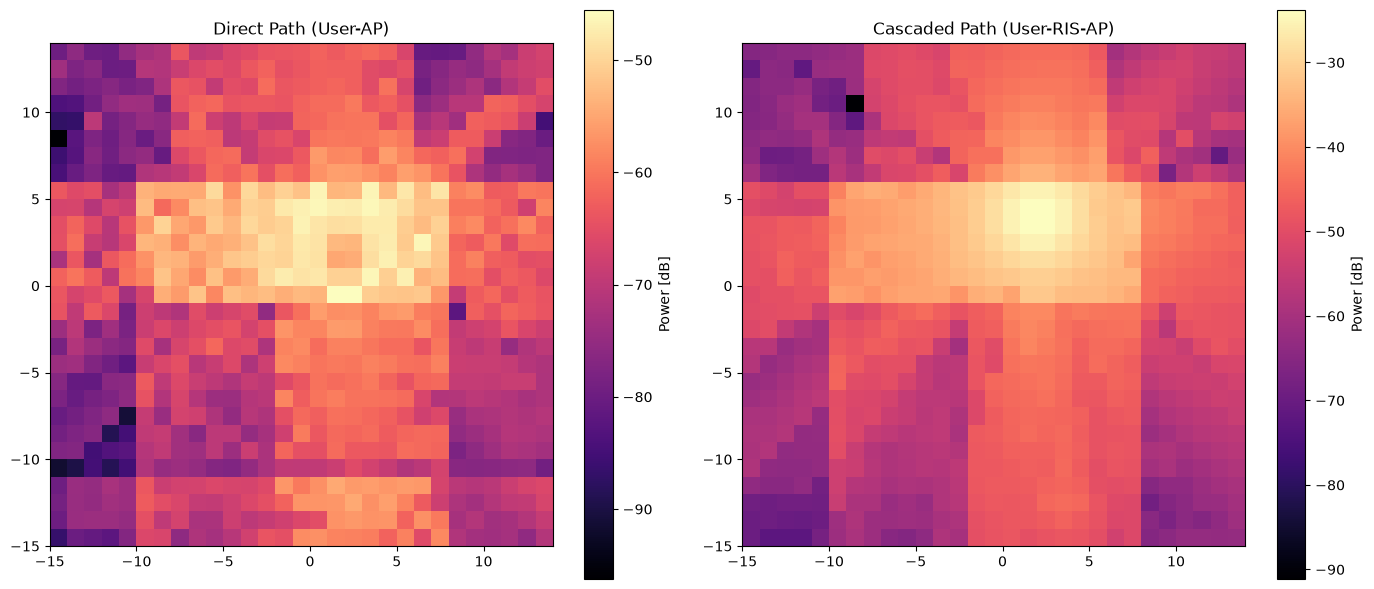

In [ ]:
# ==============================================================
# CELL 4: Cascaded Channel Analysis (User -> RIS -> AP)
# ==============================================================
import numpy as np
import matplotlib.pyplot as plt
import hdf5storage

# --- Load or pull required variables ---
try:
    _h_d, _h_ur, _h_ar, _pos = h_d, h_ur, h_ar, user_pos
except NameError:
    load_path_a = DRIVE_DIR / ('h_d_test.mat' if IS_QUICK_TEST else 'h_d.mat')
    load_path_b = DRIVE_DIR / ('h_ur_test.mat' if IS_QUICK_TEST else 'h_ur.mat')
    load_path_c = DRIVE_DIR / ('h_ar_test.mat' if IS_QUICK_TEST else 'h_ar.mat')
    _h_d = hdf5storage.loadmat(str(load_path_a))['h_d']
    _h_ur = hdf5storage.loadmat(str(load_path_b))['h_ur']
    _h_ar = hdf5storage.loadmat(str(load_path_c))['h_ar']
    _gx, _gy = hdf5storage.loadmat(str(load_path_a))['grid_x'].ravel(), hdf5storage.loadmat(str(load_path_a))['grid_y'].ravel()
    _pos = np.array([[x, y, 1.2] for x in _gx for y in _gy], dtype=np.float32)

# Dimensions check
# _h_ur: (N, num_panels, NUM_SELECTED, RIS_N)
# _h_ar: (num_panels, AP_ANTENNAS, NUM_SELECTED, RIS_N)
N_pos = _h_ur.shape[0]
num_panels = _h_ur.shape[1]
num_freq = _h_ur.shape[2]
ris_n = _h_ur.shape[3]
ap_ants = _h_ar.shape[1]

# --- Cascaded Channel Calculation ---
# For each position, panel, antenna, and frequency, we assume ideal phase alignment at the RIS
# cascaded_h = sum_{n=1}^{RIS_N} |h_ur_n * h_ar_n|
# This represents the maximum achievable gain with perfect RIS reflection
h_cascaded_amp = np.zeros((N_pos, ap_ants, num_freq), dtype=np.float32)

for p in range(num_panels):
    # Extract panel-specific channels
    # ur_p: (N, freq, RIS_N)
    ur_p = _h_ur[:, p, :, :]
    # ar_p: (AP, freq, RIS_N)
    ar_p = _h_ar[p, :, :, :]

    # Element-wise product of magnitudes for ideal combining
    # result shape: (N, AP, freq, RIS_N)
    prod = np.abs(ur_p[:, np.newaxis, :, :]) * np.abs(ar_p[np.newaxis, :, :, :])
    # Sum over RIS elements
    sum_ris = np.sum(prod, axis=-1) # (N, AP, freq)

    # Take the max over panels if multiple RIS panels exist
    h_cascaded_amp = np.maximum(h_cascaded_amp, sum_ris)

# Convert to Power [dB]
cascaded_power_lin = np.mean(h_cascaded_amp**2, axis=(1, 2)) # Avg over AP antennas and subcarriers
cascaded_power_dB = 10 * np.log10(cascaded_power_lin + 1e-30)

print(f"Cascaded Channel (User->RIS->AP) calculated for {N_pos} positions.")
print(f"  Cascaded Max: {cascaded_power_dB.max():.2f} dB")
print(f"  Cascaded Mean: {cascaded_power_dB.mean():.2f} dB")

# --- Updated Visualization ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

def plot_map(ax, vals, title):
    ux, uy = np.unique(_pos[:, 0]), np.unique(_pos[:, 1])
    if len(vals) == len(ux)*len(uy):
        grid = vals.reshape(len(uy), len(ux))
        im = ax.pcolormesh(ux, uy, grid, shading='auto', cmap='magma')
    else:
        im = ax.scatter(_pos[:len(vals), 0], _pos[:len(vals), 1], c=vals, cmap='magma', s=100)
    fig.colorbar(im, ax=ax, label='Power [dB]')
    ax.set_title(title)
    ax.set_aspect('equal')

plot_map(axes[0], direct_power_dB, "Direct Path (User-AP)")
plot_map(axes[1], cascaded_power_dB, "Cascaded Path (User-RIS-AP)")
plt.tight_layout()
plt.show()